#### Import Libraries

In [1]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.
import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict

In [2]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


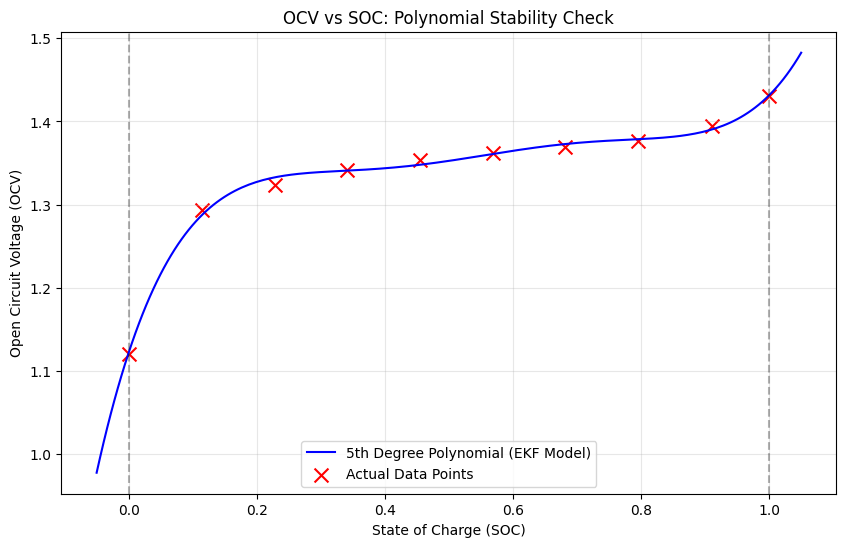

Data at 100% SOC: 1.12V
Poly at 100% SOC: 1.4315V


In [ ]:
soc_range = np.linspace(-0.05, 1.05, 200) # Slightly wider to see edge behavior
ocv_poly = p(soc_range)

# 4. Plotting
plt.figure(figsize=(10, 6))
plt.plot(soc_range, ocv_poly, 'b-', label='5th Degree Polynomial (EKF Model)')
plt.scatter(soc_points, ocv_points, color='red', marker='x', s=100, label='Actual Data Points')
 
# Formatting
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.axvline(1, color='black', linestyle='--', alpha=0.3)
plt.xlabel('State of Charge (SOC)')
plt.ylabel('Open Circuit Voltage (OCV)')
plt.title('OCV vs SOC: Polynomial Stability Check')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# 5. Check specific values at the edges
print(f"Data at 100% SOC: {ocv_points[0]}V")
print(f"Poly at 100% SOC: {p(1.0):.4f}V")

In [7]:
import EKF_Algorithm as EKF

(array(0.0258), array(1.e-05), array(8677278.), array(0.01194), array(336354.))


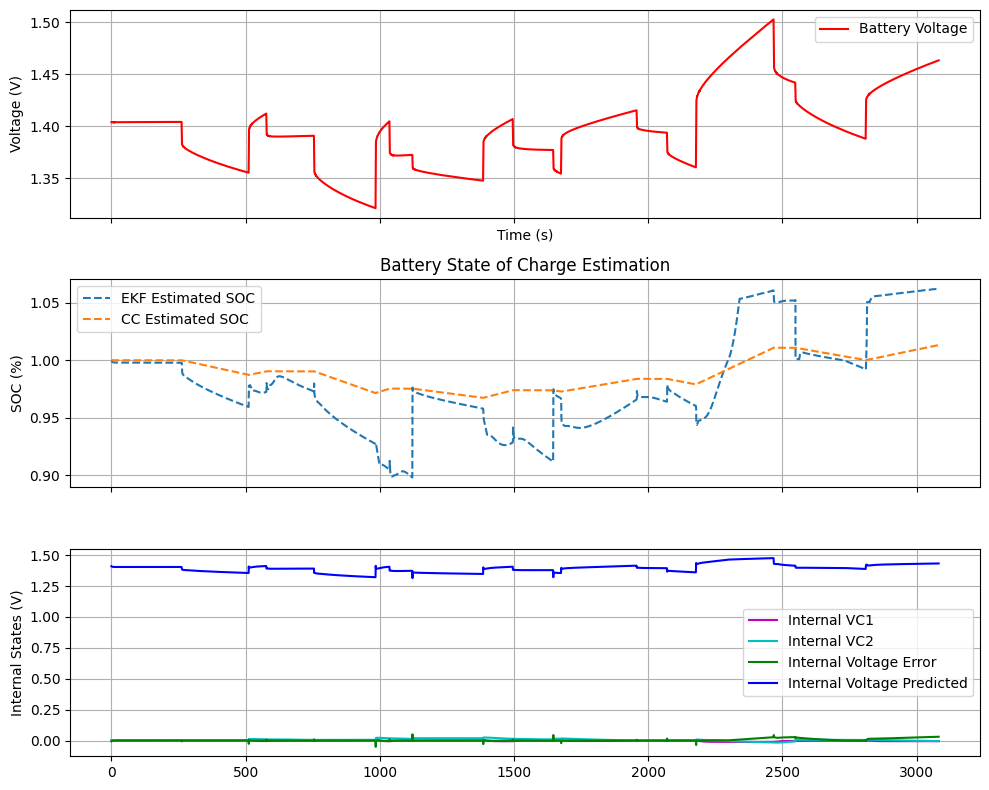

In [ ]:
# import EKF_Algorithm as EKF

import importlib
import EKF_Algorithm as EKF
importlib.reload(EKF)

# df1 = pd.read_csv("Test_1/complete.csv")
# df2 = pd.read_csv("Charging_combined/complete.csv")
# df1 = pd.read_csv("Discharging_3/complete.csv")

df1 = pd.read_csv("Discharging_2_truncated/complete.csv")
df2 = pd.read_csv("Charging_with_stops/complete.csv")
time_offset = df1["times"].iloc[-1]
df2_adjusted = df2.copy()
df2_adjusted["times"] = df2["times"] + time_offset
df = pd.concat([df1, df2_adjusted], ignore_index=True)

# df = pd.read_csv("SOC_TEST/complete.csv")

df_discharge = pd.read_csv("Discharging_2/parameters.csv")
df_charge = pd.read_csv("Charging_with_stops/parameters.csv")
# df_discharge = pd.read_csv("Discharging_2/parameters_stretched.csv")
# df_charge = pd.read_csv("Charging_with_stops/parameters_stretched.csv")
#df_charge = pd.read_csv("Charging_with_stops/parameters_fudged.csv")

#log_time_start = 950 ; log_time_end = 986
log_time_start = 500 ; log_time_end = 513


capacity = 2.35
ekf = EKF.BatteryEKF(df_charge, df_discharge, capacity)
estimated_soc = []
internal_vc1 = []
internal_vc2 = []
internal_verror = []
internal_vpredicted = []
CC_soc = []
init_soc =1
v_start = df['voltage'][0]
ekf.initialize_soc(v_start, df_charge["SOC"].values, df_charge["OCV"].values)
print(ekf.get_parameters())
#ekf.initialize_soc(v_start, df_discharge["SOC"].values, df_discharge["OCV"].values)
rest_duration = 0
counter = 0
for i in range(len(df)):
    # Calculate dt dynamically
    if i == 0:
        dt = .1 # Small default for first step
        DOD = [0]
    else:
        dt = df["times"][i] - df["times"][i-1]
        DOD.append(DOD[-1]+(df["current"][i]*(dt)/3600))
    CC_soc.append(init_soc+DOD[i]/(capacity))

    if df["current"][i] == 0:
        rest_duration += dt
    else:
        rest_duration = 0
    # Only run predict/update if dt is valid (prevents errors from duplicate timestamps)
    if dt > 0:
        log = False
        if (log_time_start <= df["times"][i] <= log_time_end):
            counter = counter+1
        if (counter == 5):
            log=True
            counter = 0
        # if (log): print(f"\nTime: {df['times'][i]}")
        # if (log): print(f"Initial State: {ekf.x}")

        ekf.predict(-df["current"][i], dt) # Positive current did = charging. Now positive current = discharging.
        # if (log): print(f"Predicted State: {ekf.x}")
        soc = ekf.update(df["voltage"][i], -df["current"][i], rest_duration)
        # if (log): print(f"Updated State: {ekf.x}")
        estimated_soc.append(soc)

        # if (log): print(f"v_prediction: {ekf.v_predicted}")
        # if (log): print(f"v_measured: {df['voltage'][i]}")

        # if (log): print(f"SOC_DISCHARGE: {ekf.soc_discharge_lut}")
        # if (log): print(f"R0_DISCHARGE: {ekf.r0_discharge_lut}")
        # if (log): print(np.interp(1, ekf.soc_discharge_lut, ekf.r0_discharge_lut))


    else:
        estimated_soc.append(estimated_soc[-1]) # Keep last value

    internal_vc1.append(ekf.x[1])
    internal_vc2.append(ekf.x[2])
    internal_vpredicted.append(ekf.v_predicted)
    internal_verror.append(df["voltage"][i] - ekf.v_predicted)

fig, (ax2, ax1, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Plot 1: SOC
ax1.plot(df["times"], estimated_soc, '--', label='EKF Estimated SOC')
ax1.plot(df["times"], CC_soc, '--', label='CC Estimated SOC')
ax1.set_ylabel('SOC (%)')
ax1.legend()
ax1.grid()
ax1.set_title('Battery State of Charge Estimation')
#ax1.set_ylim(0.8, 1.1)

# Plot 2: Voltage
ax2.plot(df["times"], df['voltage'], 'r-', label='Battery Voltage') # Changed color to red for clarity
ax2.set_ylabel('Voltage (V)')
ax2.set_xlabel('Time (s)')
ax2.legend()
ax2.grid()

# Plot 3: Internal States
ax3.plot(df["times"], internal_vc1, 'm-', label='Internal VC1')
ax3.plot(df["times"], internal_vc2, 'c-', label='Internal VC2')
ax3.plot(df["times"], internal_verror, 'g-', label='Internal Voltage Error')
ax3.plot(df["times"], internal_vpredicted, 'b-', label='Internal Voltage Predicted')
ax3.set_ylabel('Internal States (V)')
ax3.legend()
ax3.grid()
#ax3.set_xlim(0, 20)

# ax3.set_xlim(1600, 2200)
#ax3.set_ylim(-0.2, 0.2)

plt.tight_layout() # Prevents labels from overlapping
plt.show()